<a href="https://colab.research.google.com/github/FarahMandili/Firstcode_NN/blob/main/First_code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
transform = torchvision.transforms.Compose([torchvision.transforms.ToTensor(), torchvision.transforms.Normalize((0.5,),(0.5,))])
train_set = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_set = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = torch.utils.data.DataLoader(train_set, batch_size=32, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=32, shuffle=False)

100%|██████████| 9.91M/9.91M [00:00<00:00, 84.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 3.32MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 20.1MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.47MB/s]


In [ ]:
print('Number of images in the training dataset:', len(train_set))
print('Number of images in the testing dataset:', len(test_set))

Number of images in the training dataset: 60000
Number of images in the testing dataset: 10000


In [ ]:
print(f"Shape of the images in the training dataset: {train_loader.dataset[0][0].shape}")

Shape of the images in the training dataset: torch.Size([1, 28, 28])


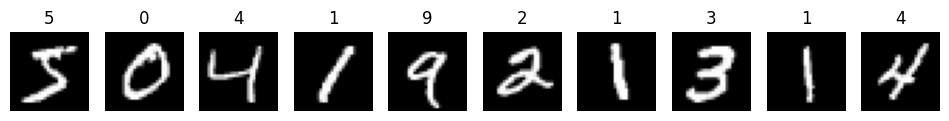

In [ ]:
fig, axes = plt.subplots(1, 10, figsize=(12, 3))
for i in range(10):
    axes[i].imshow(train_loader.dataset[i][0].squeeze(), cmap='gray')
    axes[i].set_title(train_loader.dataset[i][1])
    axes[i].axis('off')
plt.show()

In [ ]:
class NeuralNetwork(nn.Module):
    def __init__(self):
        super(NeuralNetwork, self).__init__()
        self.input = nn.Linear(28*28, 128)
        self.hidden = nn.Linear(128, 128)
        self.output = nn.Linear(128, 10)

    def forward(self, x):
        x = x.view(-1, 28*28)
        x = F.relu(self.input(x))
        x = F.relu(self.hidden(x))
        x = F.log_softmax(self.output(x), dim=1)
        return x

model = NeuralNetwork()

In [ ]:
optimizer = optim.Adam(model.parameters(), lr=0.001)

loss_function = nn.NLLLoss()

epochs = 5
for epoch in range (epochs):
    for images, labels in train_loader:
        optimizer.zero_grad()

        output = model(images)
        loss = loss_function(output, labels)

        loss.backward()
        optimizer.step()

    print (f'Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}')

Epoch [1/5], Loss: 0.1389
Epoch [2/5], Loss: 0.1774
Epoch [3/5], Loss: 0.0447
Epoch [4/5], Loss: 0.4239
Epoch [5/5], Loss: 0.2744


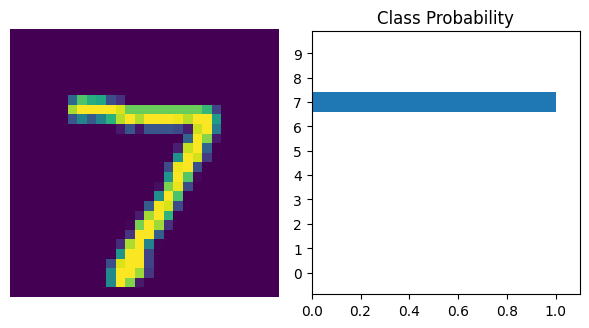

In [ ]:
def view_classify(image, probabilities):
    probabilities = probabilities.data.numpy().squeeze()

fig, (ax1, ax2) = plt.subplots(figsize=(6,9), ncols=2)

ax1.imshow(image.numpy().squeeze())
ax1.axis('off')

ax2.barh(np.arange(10), probabilities.numpy().squeeze())
ax2.set_aspect(0.1)
ax2.set_yticks(np.arange(10))
ax2.set_yticklabels(np.arange(10))
ax2.set_title('Class Probability')
ax2.set_xlim(0, 1.1)

plt.tight_layout()

tensor([[6.9215e-07, 8.4091e-07, 4.1554e-05, 2.1660e-05, 2.3108e-08, 1.5459e-07,
         1.1265e-11, 9.9991e-01, 3.2892e-07, 2.2922e-05]])


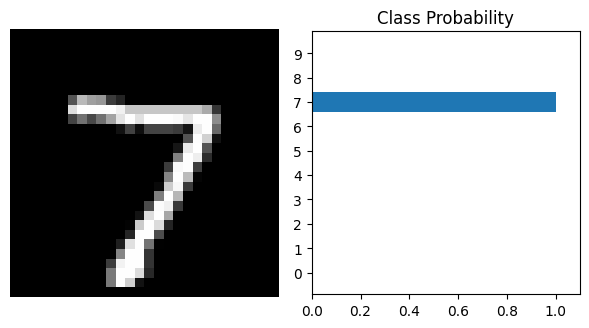

In [ ]:
images, _ = next(iter(test_loader))
image = images[0]

with torch.no_grad():
    log_probabilites = model(image.unsqueeze(0))

probabilities = torch.exp(log_probabilites)
print(probabilities)
view_classify(image.view(1, 28, 28), probabilities)